# LM24 Lab — Bayesian Inference and Shrinkage

Companion notebook to **From Calculus to Kelly, LM24**. It rebuilds the module's exhibits and computational examples from the closes of the TAIEX total-return index and of the TWSE sector indices, runs Experiments 1 and 2, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, $T$, years, $A$, $\bar R$, $s$; the sector closes with the repair cell, U28 and its halves |
| 2 | The beta–binomial update with `stats.beta` and exact `Fraction`s: Example 1, Example 2, Exhibit 2 |
| 3 | The normal mean: a `posterior` function, Example 3, Example 4, Exhibit 3, Exhibit 4 |
| 4 | Credible intervals and $\Pr(\mu\le0\mid\text{data})$: Example 5 |
| 5 | A `james_stein` function with `ddof` passed; Experiment 1 (Example 6) |
| 6 | U28's halves: Exhibit 1, Example 7, Exhibit 5, Exhibit 6, Example 8 |
| 7 | The Bayes Kelly fraction with `brentq` on shifted returns: Example 9, Example 10, Exhibit 7 |
| 8 | Practice problems 9–12, and an extension: estimating on one third of U28 and judging on the next |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`: the daily closes of the TAIEX total-return index, FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX, 2 January 2003 to 8 October 2026), `sectors_close_raw.csv` (the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column per series, empty where a series has no close) and `sectors_close_repairs.csv` (each of the 561 closes that FinMind copied from another date or series, with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns of the total-return index from 3 January 2003; years are calendar days / 365.25 and $A=T/\text{years}$. U28: the 28 leaf sector *price* indices (no dividends), closes 2008-12-01 to 2026-10-08, $T=4{,}382$ returns, $A=245.4794$ for both of LM11's halves (2,191 returns each: 2 December 2008 to 6 October 2017 and 11 October 2017 to 8 October 2026). Moments divide by the returns used (`ddof=0`); the cross-sectional SD of 28 means divides by 28. Every interval uses $\Phi^{-1}(0.975)$. TR23's posteriors are in-sample; the split-half results are out-of-sample; the reverse direction and the extension are stability checks; the Kelly results and Experiments 1 and 2 are model results; LM13's manager is hypothetical.

In [1]:
from fractions import Fraction
from math import comb, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import optimize, stats

DATA = Path("data")
EPS = 1e-12
SEED = 20261011
Z975 = stats.norm.ppf(0.975)
pl.Config.set_tbl_rows(40)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Data

TR23 first: returns between consecutive closes of the total-return index.

In [2]:
tr_df = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.Float64}).sort("date")
tr = tr_df["price"].to_numpy()
R = tr[1:] / tr[:-1] - 1
T = len(R)
d0, d1 = pl.Series([tr_df["date"][0], tr_df["date"][-1]]).str.to_date().to_list()
years = (d1 - d0).days / 365.25
A = T / years
Rbar, s, s_u = R.mean(), R.std(ddof=0), R.std(ddof=1)
se = s / sqrt(T)                         # LM20's (20.2), daily
fhat = Rbar / s**2                       # LM20's plug-in Kelly fraction


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


show("T", T, ",", "5,849")
show("years", years, ".2f", "23.76")
show("A", A, ".2f", "246.12")
show("A Rbar (%, LM19's)", 100 * A * Rbar, ".2f", "15.38")
show("sqrt(A) s (%, LM19's)", 100 * sqrt(A) * s, ".2f", "18.96")
show("SE of the annual mean (points, LM20's)", 100 * A * se, ".2f", "3.89")
show("fhat (LM20's)", fhat, ".2f", "4.28")

T: 5,849   [book: 5,849]
years: 23.76   [book: 23.76]
A: 246.12   [book: 246.12]
A Rbar (%, LM19's): 15.38   [book: 15.38]
sqrt(A) s (%, LM19's): 18.96   [book: 18.96]
SE of the annual mean (points, LM20's): 3.89   [book: 3.89]
fhat (LM20's): 4.28   [book: 4.28]


### The sector closes and the repair cell

FinMind's `TaiwanStockPrice` serves the sector indices with some rows copied from another date, or from another series on the same date (PITFALLS §3 of the repository). The book replaces each of these 561 closes with the official 13:30:00 value, as in LM16's lab. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead: a dropped close removes the returns into and out of its date, the sample shrinks from 4,382 returns, and the halves are then taken by date. Nothing is ever estimated.

In [3]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in raw.columns if c != "date"]
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
ret = closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in series]).slice(1)
smp = ret.filter(pl.all_horizontal([pl.col(c).is_not_null() for c in ["TAIEX", *U28]]))
T28, N = smp.height, len(U28)
years28 = (np.datetime64(LAST_CLOSE) - np.datetime64(FIRST_CLOSE)).astype(int) / 365.25
A28 = T28 / years28
first = smp.filter(pl.col("date") <= pl.lit("2017-10-06"))
second = smp.filter(pl.col("date") >= pl.lit("2017-10-11"))
X1, X2 = first.select(U28).to_numpy(), second.select(U28).to_numpy()
TX1, TX2 = first["TAIEX"].to_numpy(), second["TAIEX"].to_numpy()   # the TAIEX price index (no dividends)
print(f"every listed close repaired: {FULL_DATA}; U28: T = {T28}, N = {N}, A = {A28:.4f}; "
      f"halves {len(X1)} + {len(X2)}")


def show28(label, value, fmt, printed):
    # U28 numbers: assert only when every close is repaired (on the free plan the sample is smaller)
    got = format(value, fmt)
    note = "" if got == printed else ("   (differs: closes were dropped)" if not FULL_DATA else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if FULL_DATA:
        assert got == printed, (label, got, printed)


show28("T (U28)", T28, ",", "4,382")
show28("A (U28)", A28, ".4f", "245.4794")
show28("first half", len(X1), ",", "2,191")

every listed close repaired: True; U28: T = 4382, N = 28, A = 245.4794; halves 2191 + 2191
T (U28): 4,382   [book: 4,382]
A (U28): 245.4794   [book: 245.4794]
first half: 2,191   [book: 2,191]


## Part 2 — The beta–binomial update

A $\operatorname{Beta}(\alpha_0,\beta_0)$ prior and $j$ good months in $n$ give $\operatorname{Beta}(\alpha_0+j,\beta_0+n-j)$, (24.2). For integer parameters, $\Pr(\theta\le x)$ is the chance of at least $\alpha_0$ successes in $\alpha_0+\beta_0-1$ trials with probability $x$, so `Fraction` gives exact probabilities; `stats.beta` checks them.

In [4]:
def beta_sf_exact(a, b, x):
    # Pr(Beta(a, b) > x) for integer a, b: fewer than a successes in a + b - 1 trials
    n = a + b - 1
    return sum(Fraction(comb(n, k)) * x**k * (1 - x) ** (n - k) for k in range(a))


P55 = Fraction(11, 20)
a_root = optimize.brentq(lambda a: stats.beta.sf(0.55, a, a) - 0.10, 1, 1000)
show("a with 10% of managers at theta >= 0.55", a_root, ".2f", "81.96")
show("Beta(82, 82): share at theta >= 0.55 (%)", 100 * float(beta_sf_exact(82, 82, P55)), ".1f", "10.0")
show("Beta(82, 82): SD", stats.beta.std(82, 82), ".3f", "0.039")

# Example 1: 8 good months of 12 under the sceptic's prior
p_sc = beta_sf_exact(90, 86, P55)
assert abs(float(p_sc) - stats.beta.sf(0.55, 90, 86)) < 1e-12
show("Example 1 posterior mean", 90 / 176, ".4f", "0.5114")
show("   data's weight c = 12/176", 12 / 176, ".3f", "0.068")
show("   Pr(theta >= 0.55 | record) (%)", 100 * float(p_sc), ".1f", "15.3")

# Example 2: the flat prior Beta(1, 1)
p_half, p_55 = beta_sf_exact(9, 5, Fraction(1, 2)), beta_sf_exact(9, 5, P55)
print("Pr(theta > 0.5) =", p_half)
show("Example 2 Pr(theta > 0.5) (%)", 100 * float(p_half), ".1f", "86.7")
show("   Pr(theta >= 0.55) (%)", 100 * float(p_55), ".1f", "77.2")
show("   2.5% quantile", stats.beta.ppf(0.025, 9, 5), ".2f", "0.39")
show("   97.5% quantile", stats.beta.ppf(0.975, 9, 5), ".2f", "0.86")
n_need = next(n for n in range(3, 600, 3) if beta_sf_exact(82 + 2 * n // 3, 82 + n // 3, P55) > Fraction(1, 2))
show("   months of two good in three", n_need, "d", "72")
show("   Pr at 72 months (%)", 100 * float(beta_sf_exact(82 + 48, 82 + 24, P55)), ".1f", "51.2")
show("   Pr at 69 months (%)", 100 * float(beta_sf_exact(82 + 46, 82 + 23, P55)), ".1f", "49.4")

a with 10% of managers at theta >= 0.55: 81.96   [book: 81.96]
Beta(82, 82): share at theta >= 0.55 (%): 10.0   [book: 10.0]
Beta(82, 82): SD: 0.039   [book: 0.039]
Example 1 posterior mean: 0.5114   [book: 0.5114]
   data's weight c = 12/176: 0.068   [book: 0.068]
   Pr(theta >= 0.55 | record) (%): 15.3   [book: 15.3]
Pr(theta > 0.5) = 7099/8192
Example 2 Pr(theta > 0.5) (%): 86.7   [book: 86.7]
   Pr(theta >= 0.55) (%): 77.2   [book: 77.2]
   2.5% quantile: 0.39   [book: 0.39]
   97.5% quantile: 0.86   [book: 0.86]
   months of two good in three: 72   [book: 72]
   Pr at 72 months (%): 51.2   [book: 51.2]
   Pr at 69 months (%): 49.4   [book: 49.4]


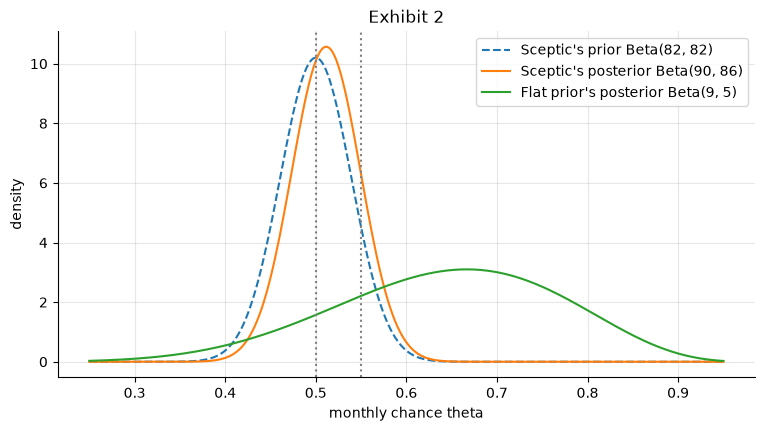

In [5]:
th = np.linspace(0.25, 0.95, 281)
fig, ax = plt.subplots()
ax.plot(th, stats.beta.pdf(th, 82, 82), "--", label="Sceptic's prior Beta(82, 82)")
ax.plot(th, stats.beta.pdf(th, 90, 86), label="Sceptic's posterior Beta(90, 86)")
ax.plot(th, stats.beta.pdf(th, 9, 5), label="Flat prior's posterior Beta(9, 5)")
for x in (0.5, 0.55):
    ax.axvline(x, color="grey", ls=":")
ax.set(xlabel="monthly chance theta", ylabel="density", title="Exhibit 2")
ax.legend(); plt.show()

## Part 3 — The normal mean with known variance

(24.3) on the annual scale: a prior SD of $A\sigma_0$ points on the annual mean against the standard error $As/\sqrt T$ = 3.89 points.

In [6]:
def weight(a_sigma0):
    # the data's weight c for a prior SD a_sigma0 on the annual mean (0.10 = 10 points)
    s0 = a_sigma0 / A
    return s0**2 / (s0**2 + se**2)


def posterior(c, a_mu0=0.0):
    # posterior mean and SD of the annual mean, (24.3), for the data's weight c and prior mean a_mu0 (annual)
    mu0 = a_mu0 / A
    return A * (mu0 + c * (Rbar - mu0)), A * sqrt(c) * se


c10 = weight(0.10)
m10, sd10 = posterior(c10)
show("Example 3 c at 10 points", c10, ".3f", "0.869")
show("   posterior mean (%)", 100 * m10, ".1f", "13.4")
show("   posterior SD (points)", 100 * sd10, ".1f", "3.6")
show("   prior worth (years)", (sqrt(A) * s / 0.10) ** 2, ".2f", "3.59")
show("knowledge check: sqrt(A) s (%), three decimals", 100 * sqrt(A) * s, ".3f", "18.957")
show("   the unrounded worth (years)", (sqrt(A) * s / 0.10) ** 2, ".3f", "3.594")
show("   the worth from the printed 18.957 (years)", (18.957 / 10) ** 2, ".3f", "3.594")
show("   years of data for c = 0.9, nine times that", 9 * (sqrt(A) * s / 0.10) ** 2, ".1f", "32.3")
show("Example 4 variance of the posterior mean (points^2)", c10 * 100, ".1f", "86.9")
show("   expected posterior variance (points^2)", 1e4 * sd10**2, ".1f", "13.1")
mh, sdh = posterior(0.5)
show("Exhibit 3 posterior mean at c = 1/2 (%)", 100 * mh, ".2f", "7.69")
show("   posterior SD (points)", 100 * sdh, ".2f", "2.75")
show("LM20's eta* = c at a prior SD equal to the mean", weight(A * Rbar), ".3f", "0.940")

Example 3 c at 10 points: 0.869   [book: 0.869]
   posterior mean (%): 13.4   [book: 13.4]
   posterior SD (points): 3.6   [book: 3.6]
   prior worth (years): 3.59   [book: 3.59]
knowledge check: sqrt(A) s (%), three decimals: 18.957   [book: 18.957]
   the unrounded worth (years): 3.594   [book: 3.594]
   the worth from the printed 18.957 (years): 3.594   [book: 3.594]
   years of data for c = 0.9, nine times that: 32.3   [book: 32.3]
Example 4 variance of the posterior mean (points^2): 86.9   [book: 86.9]
   expected posterior variance (points^2): 13.1   [book: 13.1]
Exhibit 3 posterior mean at c = 1/2 (%): 7.69   [book: 7.69]
   posterior SD (points): 2.75   [book: 2.75]
LM20's eta* = c at a prior SD equal to the mean: 0.940   [book: 0.940]


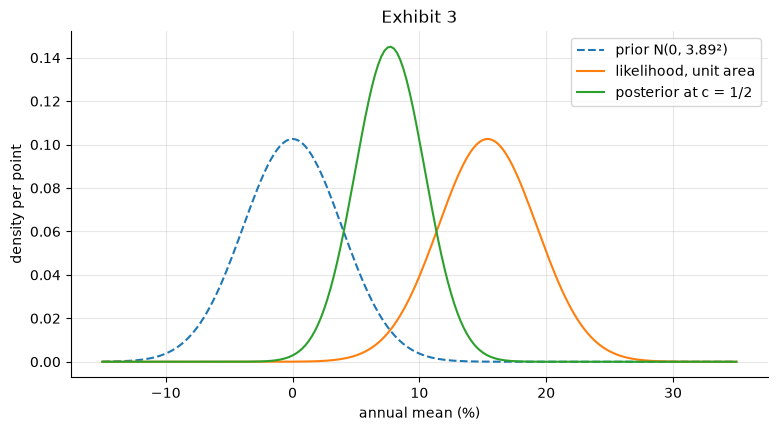

prior,A sigma0 (points),worth (years),c,posterior mean (%),lower (%),upper (%),Pr(mu<=0),Bayes fraction
str,f64,f64,f64,f64,f64,f64,f64,f64
"""quarter-Kelly sceptic""",2.245167,71.293634,0.25,3.845983,0.035085,7.65688,0.023964,1.070186
"""half-Kelly sceptic""",3.888743,23.764545,0.5,7.691965,2.302542,13.081389,0.002576,2.140373
"""10 points""",10.0,3.593751,0.868641,13.363117,6.259533,20.466702,0.000113,3.718432
"""flat""",inf,0.0,1.0,15.383931,7.762135,23.005726,0.000038,4.280745


In [7]:
x = np.linspace(-0.15, 0.35, 201)
fig, ax = plt.subplots()
ax.plot(100 * x, 0.01 * stats.norm.pdf(x, 0, A * se), "--", label="prior N(0, 3.89²)")
ax.plot(100 * x, 0.01 * stats.norm.pdf(x, A * Rbar, A * se), label="likelihood, unit area")
ax.plot(100 * x, 0.01 * stats.norm.pdf(x, mh, sdh), label="posterior at c = 1/2")
ax.set(xlabel="annual mean (%)", ylabel="density per point", title="Exhibit 3")
ax.legend(); plt.show()

rows = []
for name, s0 in (("quarter-Kelly sceptic", A * se / sqrt(3)), ("half-Kelly sceptic", A * se), ("10 points", 0.10),
                 ("flat", np.inf)):
    c = 1.0 if np.isinf(s0) else weight(s0)
    m, sd = posterior(c)
    rows.append({"prior": name, "A sigma0 (points)": 100 * s0,
                 "worth (years)": 0.0 if np.isinf(s0) else (sqrt(A) * s / s0) ** 2, "c": c,
                 "posterior mean (%)": 100 * m, "lower (%)": 100 * (m - Z975 * sd), "upper (%)": 100 * (m + Z975 * sd),
                 "Pr(mu<=0)": stats.norm.cdf(-m / sd), "Bayes fraction": c * fhat})
priors = pl.DataFrame(rows)
priors   # Exhibit 4

In [8]:
show("Exhibit 4 quarter-Kelly A sigma0", priors["A sigma0 (points)"][0], ".2f", "2.25")
show("   its worth (years)", priors["worth (years)"][0], ".2f", "71.29")
show("   the sample's span (years), four decimals", years, ".4f", "23.7645")
show("   three times the span", 3 * years, ".2f", "71.29")
show("   its interval", f"{priors['lower (%)'][0]:.1f} to {priors['upper (%)'][0]:.1f}", "", "0.0 to 7.7")
show("   its Pr(mu<=0)", priors["Pr(mu<=0)"][0], ".2g", "0.024")
show("   half-Kelly interval", f"{priors['lower (%)'][1]:.1f} to {priors['upper (%)'][1]:.1f}", "", "2.3 to 13.1")
show("   10 points: interval", f"{priors['lower (%)'][2]:.1f} to {priors['upper (%)'][2]:.1f}", "", "6.3 to 20.5")
show("   Bayes fractions", ", ".join(f"{v:.2f}" for v in priors["Bayes fraction"]), "", "1.07, 2.14, 3.72, 4.28")

Exhibit 4 quarter-Kelly A sigma0: 2.25   [book: 2.25]
   its worth (years): 71.29   [book: 71.29]
   the sample's span (years), four decimals: 23.7645   [book: 23.7645]
   three times the span: 71.29   [book: 71.29]
   its interval: 0.0 to 7.7   [book: 0.0 to 7.7]
   its Pr(mu<=0): 0.024   [book: 0.024]
   half-Kelly interval: 2.3 to 13.1   [book: 2.3 to 13.1]
   10 points: interval: 6.3 to 20.5   [book: 6.3 to 20.5]
   Bayes fractions: 1.07, 2.14, 3.72, 4.28   [book: 1.07, 2.14, 3.72, 4.28]


## Part 4 — Credible intervals and the chance of a negative mean

**Example 5.** Under the flat prior the credible interval is numerically LM20's confidence interval, and $\Pr(\mu\le0\mid\text{data})=\Phi(-\bar R/(s/\sqrt T))$. LM21's one-sided p-value divides by $s_{\mathrm u}$ instead.

In [9]:
mf, sdf = posterior(1.0)
show("Example 5 lower (%)", 100 * (mf - Z975 * sdf), ".1f", "7.8")
show("   upper (%)", 100 * (mf + Z975 * sdf), ".1f", "23.0")
print(f"Pr(mu <= 0 | data), flat prior: {stats.norm.cdf(-Rbar / se):.2e}   [book: 3.8e-05]")
t_u = Rbar / (s_u / sqrt(T))
print(f"LM21's t-stat {t_u:.6f} (with s: {Rbar / se:.6f}); one-sided p-value {stats.norm.cdf(-t_u):.2e}")
assert f"{stats.norm.cdf(-Rbar / se):.1e}" == f"{stats.norm.cdf(-t_u):.1e}" == "3.8e-05"
print(f"at 10 points: Pr(mu <= 0 | data) = {stats.norm.cdf(-m10 / sd10):.1e}   [book: 1.1e-04]")
q_m, q_sd = posterior(0.25)
h_m, h_sd = posterior(0.5)
# each sceptic's prior is centred at zero and puts 50% on mu > 0; the posterior puts much more there
show("Pr(mu > 0 | data) under the quarter-Kelly prior (%)", 100 * stats.norm.sf(-q_m / q_sd), ".1f", "97.6")
show("Pr(mu > 0 | data) under the half-Kelly prior (%)", 100 * stats.norm.sf(-h_m / h_sd), ".1f", "99.7")

Example 5 lower (%): 7.8   [book: 7.8]
   upper (%): 23.0   [book: 23.0]
Pr(mu <= 0 | data), flat prior: 3.81e-05   [book: 3.8e-05]
LM21's t-stat 3.955678 (with s: 3.956017); one-sided p-value 3.82e-05
at 10 points: Pr(mu <= 0 | data) = 1.1e-04   [book: 1.1e-04]
Pr(mu > 0 | data) under the quarter-Kelly prior (%): 97.6   [book: 97.6]
Pr(mu > 0 | data) under the half-Kelly prior (%): 99.7   [book: 99.7]


## Part 5 — James–Stein, and Experiment 1

(24.4) toward the grand mean with one common noise variance, the average of the $s_i^2/T$, treated as known. The divisor is passed explicitly.

In [10]:
def james_stein(X, ddof=0):
    # (24.4) on a T x N array of daily returns: c_hat, its unclipped 1 - c_hat, the estimates, the noise variance
    T_, N_ = X.shape
    m = X.mean(axis=0)
    noise = (X.var(axis=0, ddof=ddof) / T_).mean()
    one_minus = (N_ - 3) * noise / ((m - m.mean()) ** 2).sum()
    c_hat = max(0.0, 1 - one_minus)
    return c_hat, one_minus, m.mean() + c_hat * (m - m.mean()), noise


# the knowledge check of Section 5: four means 1, 2, 3, 6 with noise variance 1
km = np.array([1.0, 2.0, 3.0, 6.0])
kc = 1 - (4 - 3) * 1 / ((km - km.mean()) ** 2).sum()
print("c_hat =", Fraction(kc).limit_denominator(100), "| estimates", np.round(km.mean() + kc * (km - km.mean()), 2))

rng = np.random.default_rng([1, SEED])          # Experiment 1, created once
mu = rng.standard_normal((10_000, 28))          # one 10,000 x 28 array of true means,
xs = mu + rng.standard_normal((10_000, 28))     # then one of noise
gm = xs.mean(axis=1, keepdims=True)
ch = 1 - 25 / ((xs - gm) ** 2).sum(axis=1, keepdims=True)
err = {"raw": ((xs - mu) ** 2).sum(axis=1), "JS": ((gm + ch * (xs - gm) - mu) ** 2).sum(axis=1),
       "positive part": ((gm + np.maximum(ch, 0) * (xs - gm) - mu) ** 2).sum(axis=1),
       "Bayes 0.5x": ((0.5 * xs - mu) ** 2).sum(axis=1)}
for k, e in err.items():
    print(f"{k}: {e.mean():.3f} (SE {e.std(ddof=0) / sqrt(len(e)):.4f})")
show("Example 6 raw", err["raw"].mean(), ".1f", "28.1")
show("   James-Stein", err["JS"].mean(), ".1f", "15.5")
show("   positive part", err["positive part"].mean(), ".1f", "15.5")
show("   Bayes rule", err["Bayes 0.5x"].mean(), ".1f", "14.0")
c_pp = np.maximum(ch, 0)
show("   mean c_hat", c_pp.mean(), ".2f", "0.50")
show("   its standard error", c_pp.std(ddof=0) / sqrt(c_pp.size), ".3f", "0.001")

c_hat = 13/14 | estimates [1.14 2.07 3.   5.79]
raw: 28.071 (SE 0.0756)
JS: 15.542 (SE 0.0447)
positive part: 15.513 (SE 0.0441)
Bayes 0.5x: 13.995 (SE 0.0375)
Example 6 raw: 28.1   [book: 28.1]
   James-Stein: 15.5   [book: 15.5]
   positive part: 15.5   [book: 15.5]
   Bayes rule: 14.0   [book: 14.0]
   mean c_hat: 0.50   [book: 0.50]
   its standard error: 0.001   [book: 0.001]


## Part 6 — The sector halves

**Exhibit 1, Example 7, Exhibit 5, Exhibit 6, Example 8.** Annual means are $A$ (U28's) times the daily means; the miss is the root mean square over the 28 sectors.

In [11]:
m1, m2 = X1.mean(axis=0), X2.mean(axis=0)
a1, a2 = A28 * m1, A28 * m2
case = pl.DataFrame({"sector": U28, "first half (%)": 100 * a1, "second half (%)": 100 * a2})
print(case.sort("first half (%)", descending=True).head(5))
show28("correlation of the halves", np.corrcoef(a1, a2)[0, 1], ".2f", "-0.05")
show28("first-half grand mean (%)", 100 * a1.mean(), ".2f", "10.49")


def miss(m_est, m_judge, c):
    # annualized RMS miss of the shrunk estimate against the other half's means
    est = m_est.mean() + c * (m_est - m_est.mean())
    return A28 * sqrt(((est - m_judge) ** 2).mean())


show28("Exhibit 1 miss of the own means (points)", 100 * miss(m1, m2, 1), ".1f", "9.8")
show28("   miss of the grand mean (points)", 100 * miss(m1, m2, 0), ".1f", "8.5")
c_r, b_r, _, v_r = james_stein(X1)
show28("Example 7 noise (points)", 100 * A28 * sqrt(v_r), ".2f", "7.18")
show28("   spread (divisor 28, points)", 100 * a1.std(ddof=0), ".2f", "4.50")
show28("   1 - c_hat", b_r, ".2f", "2.27")
noise_i = 100 * A28 * np.sqrt(X1.var(axis=0, ddof=0) / len(X1))   # each sector's own noise (points)
show28("   smallest and largest sector noise (points)", f"{noise_i.min():.1f} to {noise_i.max():.1f}", "", "4.8 to 9.7")
show28("   ratio of the noise variances", (noise_i.max() / noise_i.min()) ** 2, ".0f", "4")
b_min = 25 * noise_i.min() ** 2 / (28 * (100 * a1.std(ddof=0)) ** 2)   # every sector at the smallest noise
print(f"   1 - c_hat if every sector had the smallest noise: {b_min:.4f} (above 1, so c_hat = 0); "
      f"from the printed 4.8 and 4.50: {25 * 4.8**2 / (28 * 4.50**2):.4f}")
assert b_min > 1 or not FULL_DATA
d1, d2 = m1 - m1.mean(), m2 - m2.mean()
show28("   best weight in hindsight", d1 @ d2 / (d1 @ d1), ".2f", "-0.09")
XD1 = X1 - X1.mean(axis=1, keepdims=True)                 # each day's cross-sectional mean removed
c_d, b_d, _, v_d = james_stein(XD1)
show28("   noise, common removed (points)", 100 * A28 * sqrt(v_d), ".2f", "4.79")
show28("   1 - c_hat, common removed", b_d, ".2f", "1.01")
show28("   second-half spread (points)", 100 * a2.std(ddof=0), ".2f", "8.49")
c_rr, _, _, _ = james_stein(X2)
c_dr, _, _, _ = james_stein(X2 - X2.mean(axis=1, keepdims=True))
show28("Example 8 c_hat", c_rr, ".2f", "0.25")
show28("   c_hat, common removed", c_dr, ".2f", "0.59")
show28("   misses at 0, c_hat, c_hat (common removed), 1",
       ", ".join(f"{100 * miss(m2, m1, c):.1f}" for c in (0, c_rr, c_dr, 1)), "", "4.5, 5.1, 6.9, 9.8")
same_side = int(((d1 >= EPS) & (d2 >= EPS)).sum() + ((d1 <= -EPS) & (d2 <= -EPS)).sum())
show28("knowledge check: same side in both halves", same_side, "d", "13")

shape: (5, 3)
┌───────────────────┬────────────────┬─────────────────┐
│ sector            ┆ first half (%) ┆ second half (%) │
│ ---               ┆ ---            ┆ ---             │
│ str               ┆ f64            ┆ f64             │
╞═══════════════════╪════════════════╪═════════════════╡
│ Automobile        ┆ 21.649935      ┆ 3.669132        │
│ Semiconductor     ┆ 16.855407      ┆ 29.640795       │
│ ElectricMachinery ┆ 16.838383      ┆ 15.174916       │
│ OtherElectronic   ┆ 16.561251      ┆ 13.910671       │
│ Rubber            ┆ 14.874939      ┆ -3.793479       │
└───────────────────┴────────────────┴─────────────────┘
correlation of the halves: -0.05   [book: -0.05]
first-half grand mean (%): 10.49   [book: 10.49]
Exhibit 1 miss of the own means (points): 9.8   [book: 9.8]
   miss of the grand mean (points): 8.5   [book: 8.5]
Example 7 noise (points): 7.18   [book: 7.18]
   spread (divisor 28, points): 4.50   [book: 4.50]
   1 - c_hat: 2.27   [book: 2.27]
   smallest and

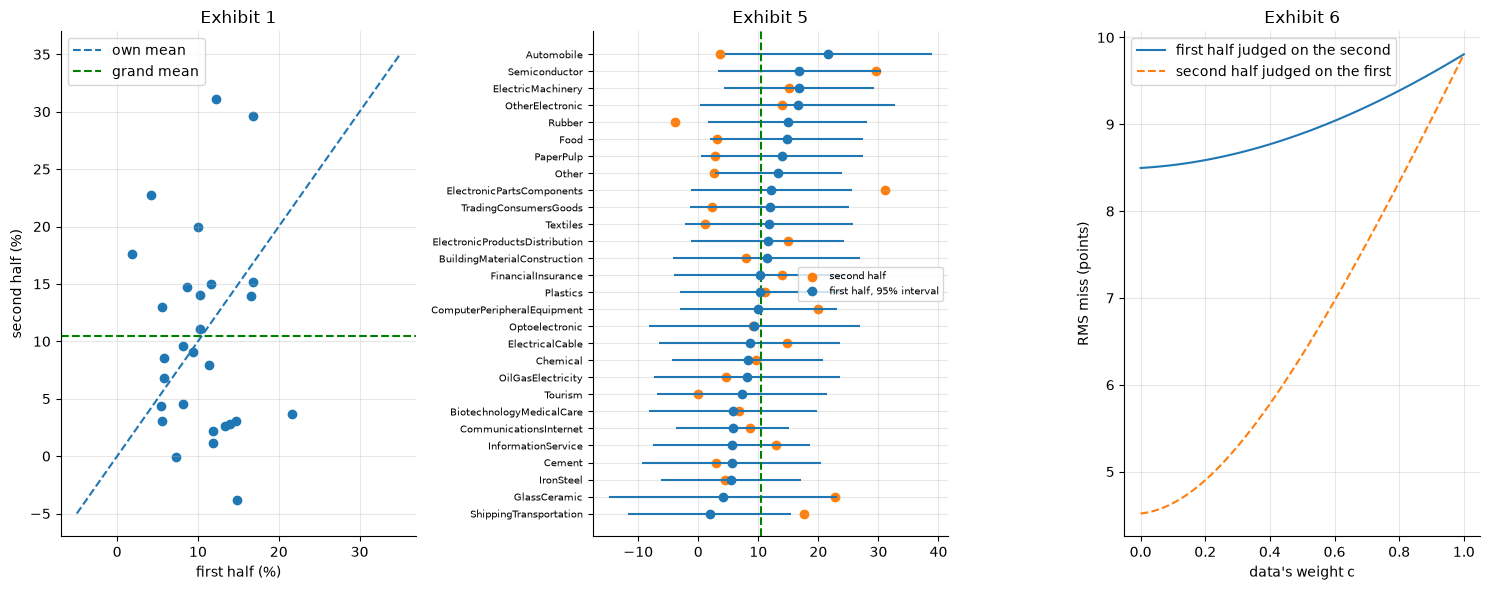

half-widths 9 to 19 points; intervals excluding the grand mean: 0


In [12]:
hw = A28 * Z975 * X1.std(axis=0, ddof=0) / sqrt(len(X1))
order = np.argsort(a1)
fig, axs = plt.subplots(1, 3, figsize=(15, 6))
axs[0].scatter(100 * a1, 100 * a2)
lim = [-5, 35]
axs[0].plot(lim, lim, "--", label="own mean")
axs[0].axhline(100 * a1.mean(), ls="--", color="green", label="grand mean")
axs[0].set(xlabel="first half (%)", ylabel="second half (%)", title="Exhibit 1"); axs[0].legend()
axs[1].errorbar(100 * a1[order], range(28), xerr=100 * hw[order], fmt="o", label="first half, 95% interval")
axs[1].scatter(100 * a2[order], range(28), color="C1", label="second half")
axs[1].axvline(100 * a1.mean(), ls="--", color="green")
axs[1].set_yticks(range(28), [U28[i] for i in order], fontsize=7); axs[1].set(title="Exhibit 5")
axs[1].legend(fontsize=7)
cs = np.linspace(0, 1, 51)
axs[2].plot(cs, [100 * miss(m1, m2, c) for c in cs], label="first half judged on the second")
axs[2].plot(cs, [100 * miss(m2, m1, c) for c in cs], "--", label="second half judged on the first")
axs[2].set(xlabel="data's weight c", ylabel="RMS miss (points)", title="Exhibit 6"); axs[2].legend()
plt.tight_layout(); plt.show()
print(f"half-widths {100 * hw.min():.0f} to {100 * hw.max():.0f} points; intervals excluding the grand mean: "
      f"{int((np.abs(a1 - a1.mean()) >= hw + EPS).sum())}")

## Part 7 — The Bayes Kelly fraction

(24.5): $f_{\mathrm B}=c\hat f$ for a prior centred at zero. The exact fraction solves (4.5) on TR23's returns shifted by one constant to the posterior mean, LM4's band method. To see what the quadratic rule's overshoot at $c=1$ is made of, the cell keeps (4.2)'s $\mu^2$ term, then mirrors the days about their mean: the mirrored days keep the fat tails and lose the skewness.

In [13]:
def kelly_exact(target):
    # root of (4.5) on TR23's returns shifted so that their mean is `target` (daily)
    x = R - Rbar + target
    return optimize.brentq(lambda f: (x / (1 + f * x)).mean(), 1e-6, 1 / abs(x.min()) - 1e-6)


f_star = kelly_exact(Rbar)
show("LM17's exact in-sample root", f_star, ".4f", "4.1381")
show("Example 9 c fhat at 10 points", c10 * fhat, ".2f", "3.72")
show("   exact on shifted returns", kelly_exact(c10 * Rbar), ".2f", "3.62")
xg, wg = np.polynomial.hermite_e.hermegauss(60)
wg = wg / wg.sum()
pm_d, psd_d = c10 * Rbar, sqrt(c10) * se


def dgrowth(f):
    # derivative of the empirical growth averaged over the posterior of mu (60-node Gauss-Hermite quadrature)
    return sum(w * ((R - Rbar + pm_d + psd_d * z) / (1 + f * (R - Rbar + pm_d + psd_d * z))).mean()
               for w, z in zip(wg, xg))


show("   posterior-integrated", optimize.brentq(dgrowth, 1e-6, 8), ".2f", "3.62")
show("   posterior SD of mu / sigma^2", psd_d / s**2, ".2f", "1.01")
show("   quadratic minus exact at c = 1/2", 0.5 * fhat - kelly_exact(0.5 * Rbar), ".2f", "0.03")

# what the gap at c = 1 is made of: (4.2) keeps a mu^2 term that (24.5) drops; the rest comes from non-normal days
quad_mu2 = Rbar / (s**2 + Rbar**2)
show("   (4.2) with its mu^2 term, c = 1", quad_mu2, ".2f", "4.27")
show("   mu^2 part of the gap", fhat - quad_mu2, ".2f", "0.01")
show("   the rest (non-normal days)", quad_mu2 - f_star, ".2f", "0.13")
sym = np.concatenate([R, 2 * Rbar - R])         # the days mirrored about their mean: same tails, no skewness
f_sym = optimize.brentq(lambda f: (sym / (1 + f * sym)).mean(), 1e-6, 1 / abs(sym.min()) - 1e-6)
print(f"   mirrored days' root {f_sym:.4f}: fat tails {quad_mu2 - f_sym:.4f}, skewness {f_sym - f_star:.4f}")
print(f"   skewness of TR23's daily returns (LM19's): {(((R - Rbar) / s) ** 3).mean():.4f}")


def growth(f, m):
    # posterior-expected annual log growth in the model, posterior mean m per day
    return A * (f * m - f**2 * s**2 / 2)


show("   expected growth at f_B (%)", 100 * growth(c10 * fhat, pm_d), ".0f", "25")
show("   plug-in's share (%)", 100 * growth(fhat, pm_d) / growth(c10 * fhat, pm_d), ".1f", "97.7")
show("Example 10 Bayes growth, half Kelly (%)", 100 * growth(0.5 * fhat, 0.5 * Rbar), ".1f", "8.2")
show("   plug-in growth, quarter Kelly (%)", 100 * growth(fhat, 0.25 * Rbar), ".1f", "-16.5")
show("   Bayes growth, quarter Kelly (%)", 100 * growth(0.25 * fhat, 0.25 * Rbar), ".2f", "2.06")

LM17's exact in-sample root: 4.1381   [book: 4.1381]
Example 9 c fhat at 10 points: 3.72   [book: 3.72]
   exact on shifted returns: 3.62   [book: 3.62]
   posterior-integrated: 3.62   [book: 3.62]
   posterior SD of mu / sigma^2: 1.01   [book: 1.01]
   quadratic minus exact at c = 1/2: 0.03   [book: 0.03]
   (4.2) with its mu^2 term, c = 1: 4.27   [book: 4.27]
   mu^2 part of the gap: 0.01   [book: 0.01]
   the rest (non-normal days): 0.13   [book: 0.13]
   mirrored days' root 4.2075: fat tails 0.0618, skewness 0.0694
   skewness of TR23's daily returns (LM19's): -0.3384
   expected growth at f_B (%): 25   [book: 25]
   plug-in's share (%): 97.7   [book: 97.7]
Example 10 Bayes growth, half Kelly (%): 8.2   [book: 8.2]
   plug-in growth, quarter Kelly (%): -16.5   [book: -16.5]
   Bayes growth, quarter Kelly (%): 2.06   [book: 2.06]


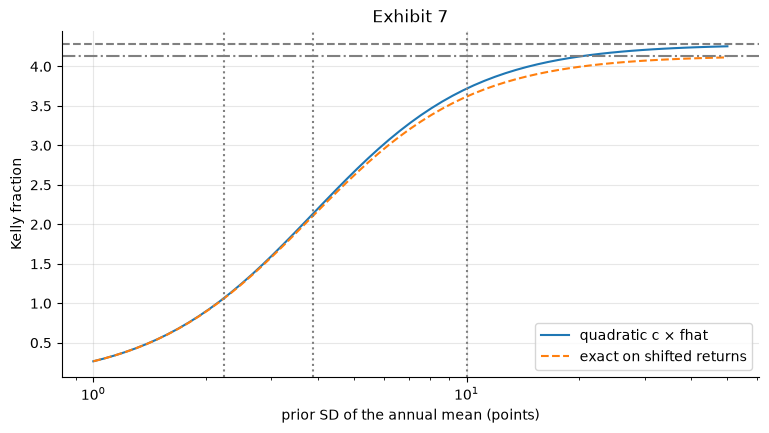

In [14]:
grid = np.geomspace(1, 50, 61)
quad = [weight(g / 100) * fhat for g in grid]
exact = [kelly_exact(weight(g / 100) * Rbar) for g in grid]
fig, ax = plt.subplots()
ax.semilogx(grid, quad, label="quadratic c × fhat")
ax.semilogx(grid, exact, "--", label="exact on shifted returns")
for g in (100 * A * se / sqrt(3), 100 * A * se, 10):
    ax.axvline(g, color="grey", ls=":")
ax.axhline(fhat, color="grey", ls="--"); ax.axhline(f_star, color="grey", ls="-.")
ax.set(xlabel="prior SD of the annual mean (points)", ylabel="Kelly fraction", title="Exhibit 7")
ax.legend(); plt.show()

## Part 8 — Practice problems 9–12

**Problem 9.** A prior centred at zero with $A\sigma_0=5$ points.

In [15]:
c5 = weight(0.05)
m5, sd5 = posterior(c5)
show("P9 c", c5, ".3f", "0.623")
show("   posterior mean (%)", 100 * m5, ".1f", "9.6")
show("   posterior SD (points)", 100 * sd5, ".1f", "3.1")
show("   from the printed 0.623: mean, two decimals", 0.623 * 15.38, ".2f", "9.58")
show("   SD, two decimals", sqrt(0.623) * 3.89, ".2f", "3.07")
show("   interval from 9.58 and 3.07", f"{9.58 - 1.96 * 3.07:.1f} to {9.58 + 1.96 * 3.07:.1f}", "", "3.6 to 15.6")
show("   interval (%)", f"{100 * (m5 - Z975 * sd5):.1f} to {100 * (m5 + Z975 * sd5):.1f}", "", "3.6 to 15.6")
show("   Pr(mu <= 0 | data)", stats.norm.cdf(-m5 / sd5), ".4f", "0.0009")
show("   Bayes fraction", c5 * fhat, ".2f", "2.67")
show("   prior worth (years)", (sqrt(A) * s / 0.05) ** 2, ".1f", "14.4")

P9 c: 0.623   [book: 0.623]
   posterior mean (%): 9.6   [book: 9.6]
   posterior SD (points): 3.1   [book: 3.1]
   from the printed 0.623: mean, two decimals: 9.58   [book: 9.58]
   SD, two decimals: 3.07   [book: 3.07]
   interval from 9.58 and 3.07: 3.6 to 15.6   [book: 3.6 to 15.6]
   interval (%): 3.6 to 15.6   [book: 3.6 to 15.6]
   Pr(mu <= 0 | data): 0.0009   [book: 0.0009]
   Bayes fraction: 2.67   [book: 2.67]
   prior worth (years): 14.4   [book: 14.4]


**Problem 10.** Experiment 2: one generator, the spreads 0, 1 and 3 in that order, true means drawn even at spread 0.

In [16]:
rng = np.random.default_rng([2, SEED])          # Experiment 2, created once
for spread, book in ((0.0, ("28.0", "3.0", "2.1")), (1.0, ("28.0", "15.5", "15.5")), (3.0, ("28.0", "25.5", "25.5"))):
    mu = spread * rng.standard_normal((20_000, 28))
    xs = mu + rng.standard_normal((20_000, 28))
    gm = xs.mean(axis=1, keepdims=True)
    ch = 1 - 25 / ((xs - gm) ** 2).sum(axis=1, keepdims=True)
    e = [((xs - mu) ** 2).sum(axis=1), ((gm + ch * (xs - gm) - mu) ** 2).sum(axis=1),
         ((gm + np.maximum(ch, 0) * (xs - gm) - mu) ** 2).sum(axis=1)]
    out = ", ".join(f"{v.mean():.1f}" for v in e)
    ses = ", ".join(f"{v.std(ddof=0) / sqrt(len(v)):.3f}" for v in e)
    show(f"P10 spread {spread:g}: raw, JS, positive part", out, "", ", ".join(book))
    print(f"   standard errors {ses}; theory for JS {28 - 25 / (1 + spread**2):g}")

P10 spread 0: raw, JS, positive part: 28.0, 3.0, 2.1   [book: 28.0, 3.0, 2.1]
   standard errors 0.053, 0.023, 0.018; theory for JS 3
P10 spread 1: raw, JS, positive part: 28.0, 15.5, 15.5   [book: 28.0, 15.5, 15.5]
   standard errors 0.053, 0.031, 0.031; theory for JS 15.5
P10 spread 3: raw, JS, positive part: 28.0, 25.5, 25.5   [book: 28.0, 25.5, 25.5]
   standard errors 0.052, 0.048, 0.048; theory for JS 25.5


**Problem 11.** Each day's return of the TAIEX price index subtracted instead of the cross-sectional mean (*stability check*).

In [17]:
XE1, XE2 = X1 - TX1[:, None], X2 - TX2[:, None]
c_e, b_e, _, v_e = james_stein(XE1)
me1, me2 = XE1.mean(axis=0), XE2.mean(axis=0)
show28("P11 noise (points)", 100 * A28 * sqrt(v_e), ".1f", "5.0")
show28("   1 - c_hat", b_e, ".2f", "1.10")
show28("   miss of the grand mean (points)", 100 * miss(me1, me2, 0), ".1f", "12.1")
dev_miss = miss(me1 - me1.mean(), me2 - me2.mean(), 0)  # the grand mean's miss of the deviations
show28("   miss of the deviations from each half's grand mean (points)", 100 * dev_miss, ".2f", "8.49")
show28("   average excess, first half (points)", 100 * A28 * me1.mean(), ".1f", "-0.3")
show28("   average excess, second half (points)", 100 * A28 * me2.mean(), ".1f", "-9.0")
show28("   TAIEX price index, halves (%)", f"{100 * A28 * TX1.mean():.1f} -> {100 * A28 * TX2.mean():.1f}", "",
       "10.8 -> 19.1")

P11 noise (points): 5.0   [book: 5.0]
   1 - c_hat: 1.10   [book: 1.10]
   miss of the grand mean (points): 12.1   [book: 12.1]
   miss of the deviations from each half's grand mean (points): 8.49   [book: 8.49]
   average excess, first half (points): -0.3   [book: -0.3]
   average excess, second half (points): -9.0   [book: -9.0]
   TAIEX price index, halves (%): 10.8 -> 19.1   [book: 10.8 -> 19.1]


**Problem 12.** LM13's Practice Problem 8, 16 good months in 24, under the sceptic's prior.

In [18]:
p12 = beta_sf_exact(98, 90, P55)
show("P12 posterior mean", 98 / 188, ".3f", "0.521")
show("   Pr(theta >= 0.55 | record) (%)", 100 * float(p12), ".1f", "21.6")

P12 posterior mean: 0.521   [book: 0.521]
   Pr(theta >= 0.55 | record) (%): 21.6   [book: 21.6]


### Extension: thirds of U28 (*stability check*)

Split U28 into thirds with `np.array_split` (1,461, 1,461 and 1,460 returns). Estimate $\hat c$ on each third and judge the shrunk means on the next third, as in Example 7; the cell also prints each pair's correlation of the means and hindsight slope, which Section 6 quotes. Does any third give partial shrinkage, and does it predict the next third better than the grand mean? Then explain why a second split of the same data is a stability check and not a new test: the thirds were chosen after the halves were seen, and they reuse the same 4,382 days (LM21 counts such looks).

In [19]:
Xall = smp.select(U28).to_numpy()
parts = np.array_split(Xall, 3)
print("third lengths:", [len(p) for p in parts])
for k, book in enumerate((("0.13", "0.09"), ("0.24", "0.61"))):
    c_k, _, _, _ = james_stein(parts[k])
    mk, mn = parts[k].mean(axis=0), parts[k + 1].mean(axis=0)
    print(f"third {k + 1} -> {k + 2}: c_hat {c_k:.2f}; miss at 0 {100 * miss(mk, mn, 0):.1f}, "
          f"at c_hat {100 * miss(mk, mn, c_k):.1f}, at 1 {100 * miss(mk, mn, 1):.1f} points")
    dk, dn = mk - mk.mean(), mn - mn.mean()
    show28("   correlation of the means", np.corrcoef(mk, mn)[0, 1], ".2f", book[0])
    show28("   hindsight slope (best weight)", dk @ dn / (dk @ dk), ".2f", book[1])
# your code: repeat with each day's cross-sectional mean removed

third lengths: [1461, 1461, 1460]
third 1 -> 2: c_hat 0.00; miss at 0 10.3, at c_hat 10.3, at 1 11.8 points
   correlation of the means: 0.13   [book: 0.13]
   hindsight slope (best weight): 0.09   [book: 0.09]
third 2 -> 3: c_hat 0.00; miss at 0 15.1, at c_hat 15.1, at 1 14.9 points
   correlation of the means: 0.24   [book: 0.24]
   hindsight slope (best weight): 0.61   [book: 0.61]
